In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

In [17]:
data = pd.read_excel('/content/Spotify Streaming.xlsx')

In [6]:
data.shape

(50000, 31)

In [7]:
data.head()

,Stream ID,User ID,Track ID,Track Name,Artist ID,Artist Name,Album Name,Genre,Mood,Play Date,...,Is Skipped,Skip Reason,Is Completed,Is Replayed,Is Liked,Added To Playlist,Stream Quality,Ad Played,Listening Minutes,Estimated Revenue USD
0,STR00000001,USR139937,TRK10042,Higher Ground,ART5005,The Weekenders,Summer Tape,Lo-fi,Energetic,2025-01-16,...,No,Not Skipped,No,No,No,No,Normal,No,4.37,0.0137
1,STR00000002,USR102268,TRK10032,Blue Horizon,ART5015,Blue Static,Quiet Places,Indie,Melancholic,2025-08-19,...,No,Not Skipped,No,No,No,No,High,No,3.55,0.0126
2,STR00000003,USR127523,TRK10085,Stay a Little,ART5012,Indigo Avenue,Acoustic Sessions,Hip-Hop,Energetic,2026-04-01,...,No,Not Skipped,No,No,No,No,High,No,4.85,0.0124
3,STR00000004,USR105448,TRK10133,Midnight Drive,ART5018,Mira Sol,Golden Records,Latin,Energetic,2026-04-01,...,No,Not Skipped,No,Yes,No,No,Very High,No,3.88,0.0087
4,STR00000005,USR133513,TRK10199,Higher Ground,ART5006,Mason Wilde,Acoustic Sessions,Country,Melancholic,2024-06-29,...,No,Not Skipped,No,No,Yes,Yes,Normal,No,2.83,0.0062


In [8]:
data.tail()

,Stream ID,User ID,Track ID,Track Name,Artist ID,Artist Name,Album Name,Genre,Mood,Play Date,...,Is Skipped,Skip Reason,Is Completed,Is Replayed,Is Liked,Added To Playlist,Stream Quality,Ad Played,Listening Minutes,Estimated Revenue USD
49995,STR00049996,USR123909,TRK10107,Neon Lights,ART5006,Kai Rivers,After Hours,Country,Energetic,2024-11-05,...,No,Not Skipped,Yes,No,No,No,Normal,No,4.08,0.0089
49996,STR00049997,USR100500,TRK10119,Lost in Time,ART5005,Arlo Grey,Acoustic Sessions,Indie,Focus,2025-02-19,...,No,Not Skipped,No,No,No,No,Normal,No,1.37,0.0150
49997,STR00049998,USR112368,TRK10194,No Turning Back,ART5016,Arlo Grey,After Hours,Afrobeats,Acoustic,2025-08-07,...,No,Not Skipped,No,No,No,No,Very High,Yes,3.42,0.0169
49998,STR00049999,USR120811,TRK10005,Summer Again,ART5013,Nova Lane,Blue Rooms,Country,Acoustic,2026-04-24,...,No,Not Skipped,No,Yes,Yes,Yes,High,No,1.75,0.0062
49999,STR00050000,USR120010,TRK10108,Paper Planes,ART5020,The Paper Moons,City Lights,Afrobeats,Melancholic,2024-09-14,...,No,Not Skipped,No,No,Yes,Yes,Very High,No,2.62,0.0031


In [9]:
data.describe()

,Play Date,Play Hour,Track Duration Sec,Played Duration Sec,Completion Rate,Listening Minutes,Estimated Revenue USD
count,50000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2025-05-31 10:39:44.064000,14.112280,239.67924,170.618760,0.711937,2.843635,0.007050
min,2024-01-01 00:00:00,0.000000,120.00000,19.000000,0.083000,0.320000,0.000000
25%,2024-09-17 00:00:00,9.000000,179.00000,120.000000,0.608000,2.000000,0.002700
50%,2025-06-01 00:00:00,15.000000,240.00000,164.000000,0.734000,2.730000,0.007000
75%,2026-02-13 00:00:00,19.000000,300.00000,217.000000,0.836000,3.620000,0.011300
max,2026-10-27 00:00:00,23.000000,360.00000,356.000000,0.996000,5.930000,0.020000
std,NaN,5.908138,69.91979,63.760439,0.159631,1.062678,0.005168


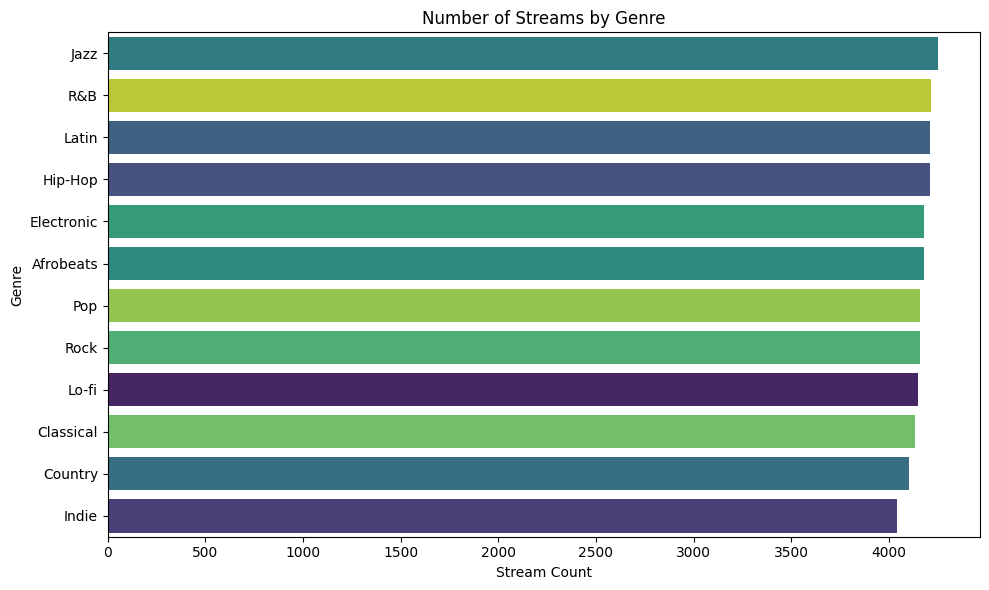

In [18]:
#bar graph
plt.figure(figsize=(10, 6))
sn.countplot(data=data, y='Genre', order=data['Genre'].value_counts().index, hue='Genre', palette='viridis', legend=False)
plt.title('Number of Streams by Genre')
plt.xlabel('Stream Count')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [19]:
# Calculate and display average revenue per genre
avg_revenue_genre = data.groupby('Genre')['Estimated Revenue USD'].mean().sort_values(ascending=False).reset_index()

# Display the resulting DataFrame
display(avg_revenue_genre)

,Genre,Estimated Revenue USD
0,Country,0.007195
1,Indie,0.007126
2,Afrobeats,0.007125
3,R&B,0.007121
4,Lo-fi,0.007091
5,Rock,0.007066
6,Pop,0.007021
7,Jazz,0.006999
8,Electronic,0.006995
9,Hip-Hop,0.006974


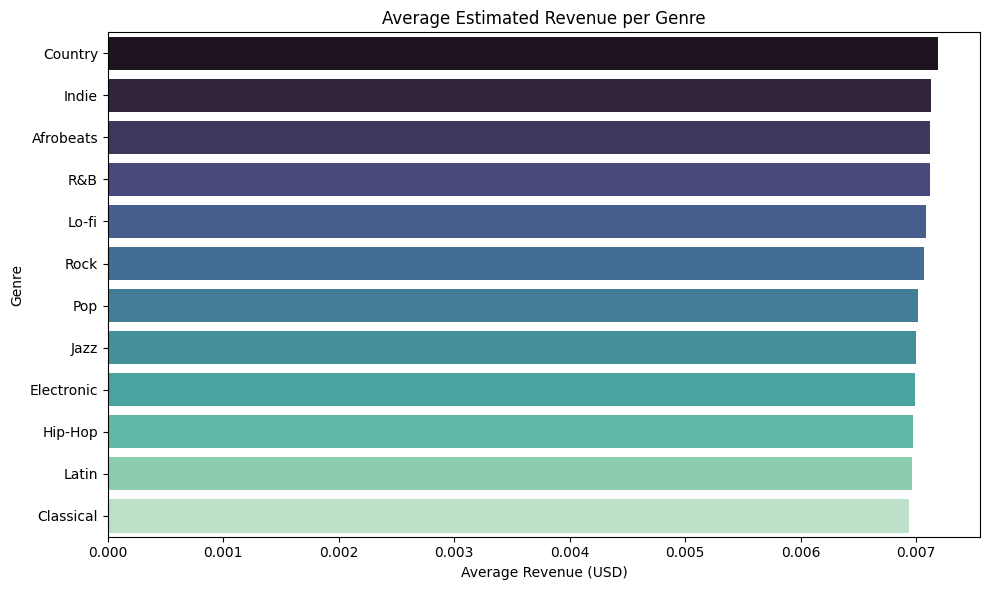

In [20]:
#Create a bar plot to visualise the average revenue per genre
plt.figure(figsize=(10, 6))
sn.barplot(data=avg_revenue_genre, x='Estimated Revenue USD', y='Genre', hue='Genre', palette='mako', legend=False)
plt.title('Average Estimated Revenue per Genre')
plt.xlabel('Average Revenue (USD)')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [21]:
# Calculate the correlation coefficient
correlation = data['Listening Minutes'].corr(data['Estimated Revenue USD'])
print(f"Correlation between Listening Minutes and Estimated Revenue USD: {correlation:.4f}")

Correlation between Listening Minutes and Estimated Revenue USD: 0.0017


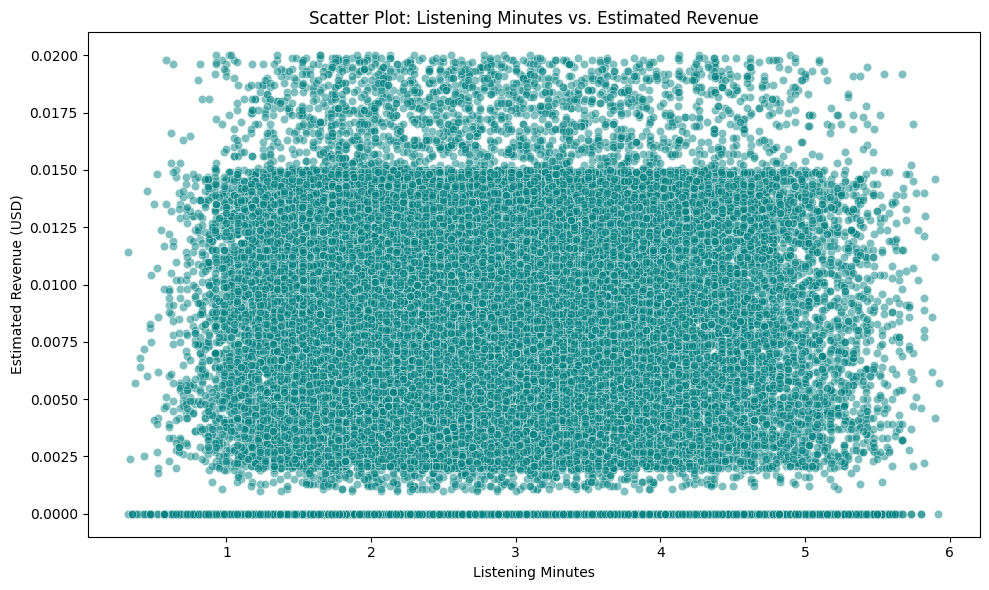

In [23]:
# Create a scatter plot of Listening Minutes vs Estimated Revenue USD
plt.figure(figsize=(10, 6))
sn.scatterplot(data=data, x='Listening Minutes', y='Estimated Revenue USD', alpha=0.5, color='teal')
plt.title('Scatter Plot: Listening Minutes vs. Estimated Revenue')
plt.xlabel('Listening Minutes')
plt.ylabel('Estimated Revenue (USD)')
plt.tight_layout()
plt.show()

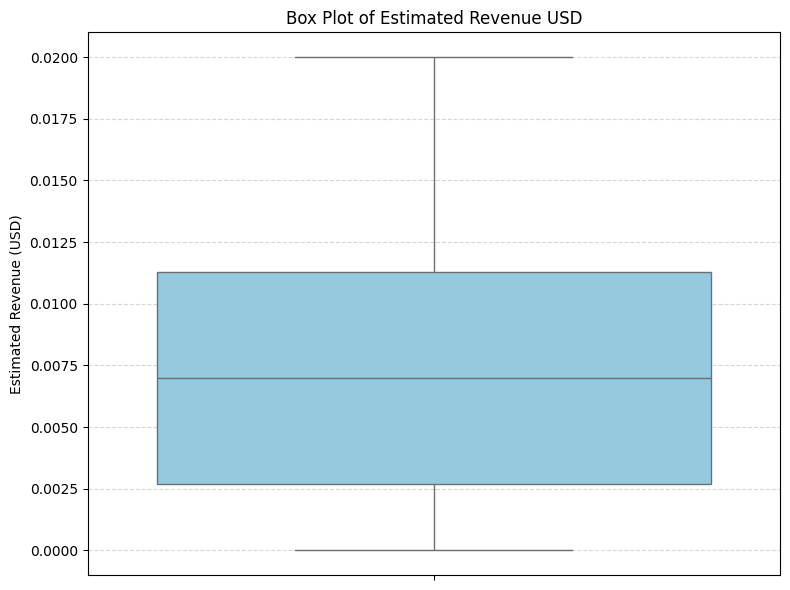

In [24]:
import matplotlib.pyplot as plt
import seaborn as sn

# Create a box plot of Estimated Revenue USD
plt.figure(figsize=(8, 6))
sn.boxplot(data=data, y='Estimated Revenue USD', color='skyblue')
plt.title('Box Plot of Estimated Revenue USD')
plt.ylabel('Estimated Revenue (USD)')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [25]:
# Group by 'Stream Quality' and calculate mean estimated revenue
revenue_by_quality = data.groupby('Stream Quality')['Estimated Revenue USD'].mean().sort_values(ascending=False).reset_index()

# Display the results
display(revenue_by_quality)

,Stream Quality,Estimated Revenue USD
0,Low,0.007194
1,Lossless,0.007111
2,High,0.007060
3,Normal,0.007026
4,Very High,0.006986


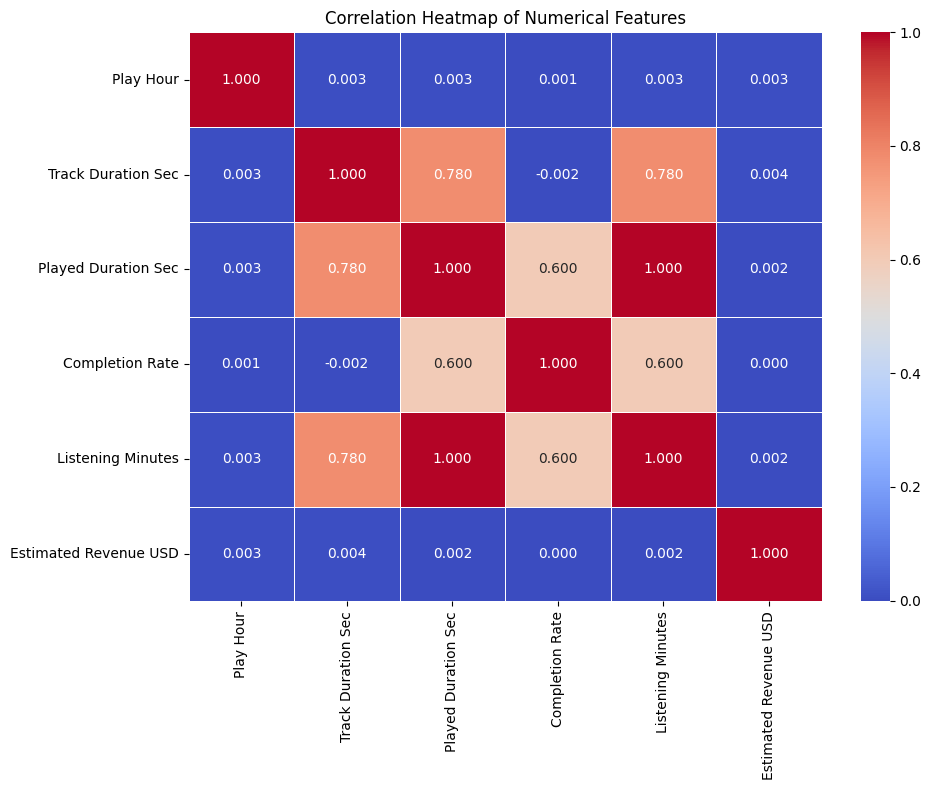

In [26]:
# Select only numerical columns
numerical_data = data.select_dtypes(include=['float64', 'int64'])

# Compute the correlation matrix
corr_matrix = numerical_data.corr()

# Create a heatmap
plt.figure(figsize=(10, 8))
sn.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

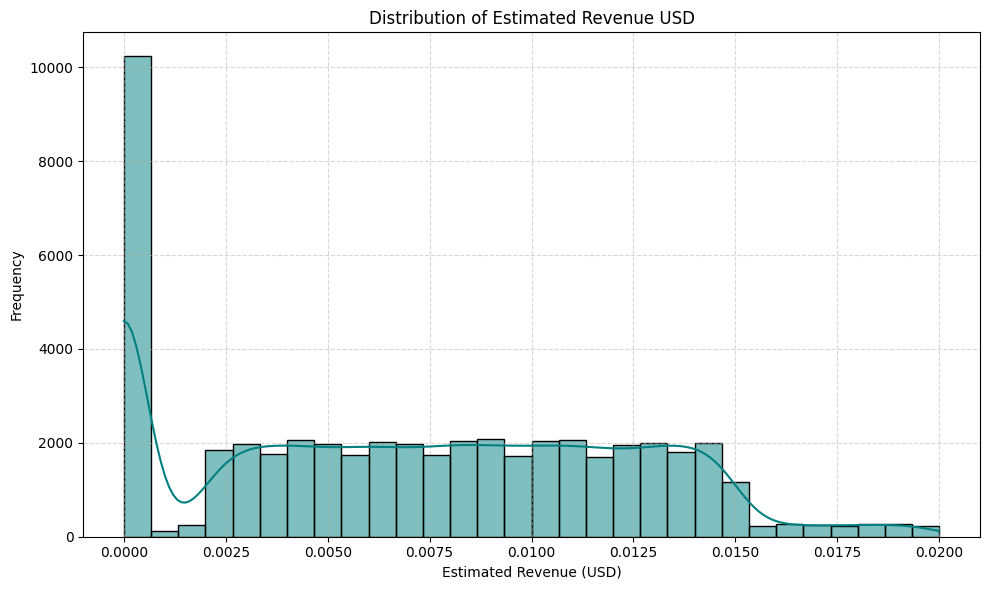

In [27]:
# Plot a histogram of Estimated Revenue USD to view its distribution
plt.figure(figsize=(10, 6))
sn.histplot(data=data, x='Estimated Revenue USD', bins=30, kde=True, color='teal')
plt.title('Distribution of Estimated Revenue USD')
plt.xlabel('Estimated Revenue (USD)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [28]:
# Calculate total estimated revenue by artist
top_artists_revenue = data.groupby('Artist Name')['Estimated Revenue USD'].sum().sort_values(ascending=False).reset_index().head(10)

# Display the top 10 artists
display(top_artists_revenue)

,Artist Name,Estimated Revenue USD
0,Indigo Avenue,18.6421
1,Arlo Grey,18.4355
2,Mason Wilde,18.4036
3,The Paper Moons,18.0836
4,The Weekenders,18.0045
5,Atlas Bloom,17.9065
6,Mira Sol,17.8910
7,Blue Static,17.8873
8,City Signals,17.8001
9,Nova Lane,17.7216


In [29]:
# Calculate total estimated revenue for all artists
artist_revenue = data.groupby('Artist Name')['Estimated Revenue USD'].sum().sort_values(ascending=False).reset_index()

# Extract top 10 and bottom 10
top_10 = artist_revenue.head(10).copy()
top_10['Group'] = 'Top 10'

bottom_10 = artist_revenue.tail(10).copy()
bottom_10['Group'] = 'Bottom 10'

# Combine for display and plotting
comparison_df = pd.concat([top_10, bottom_10])
display(comparison_df)

,Artist Name,Estimated Revenue USD,Group
0,Indigo Avenue,18.6421,Top 10
1,Arlo Grey,18.4355,Top 10
2,Mason Wilde,18.4036,Top 10
3,The Paper Moons,18.0836,Top 10
4,The Weekenders,18.0045,Top 10
5,Atlas Bloom,17.9065,Top 10
6,Mira Sol,17.8910,Top 10
7,Blue Static,17.8873,Top 10
8,City Signals,17.8001,Top 10
9,Nova Lane,17.7216,Top 10


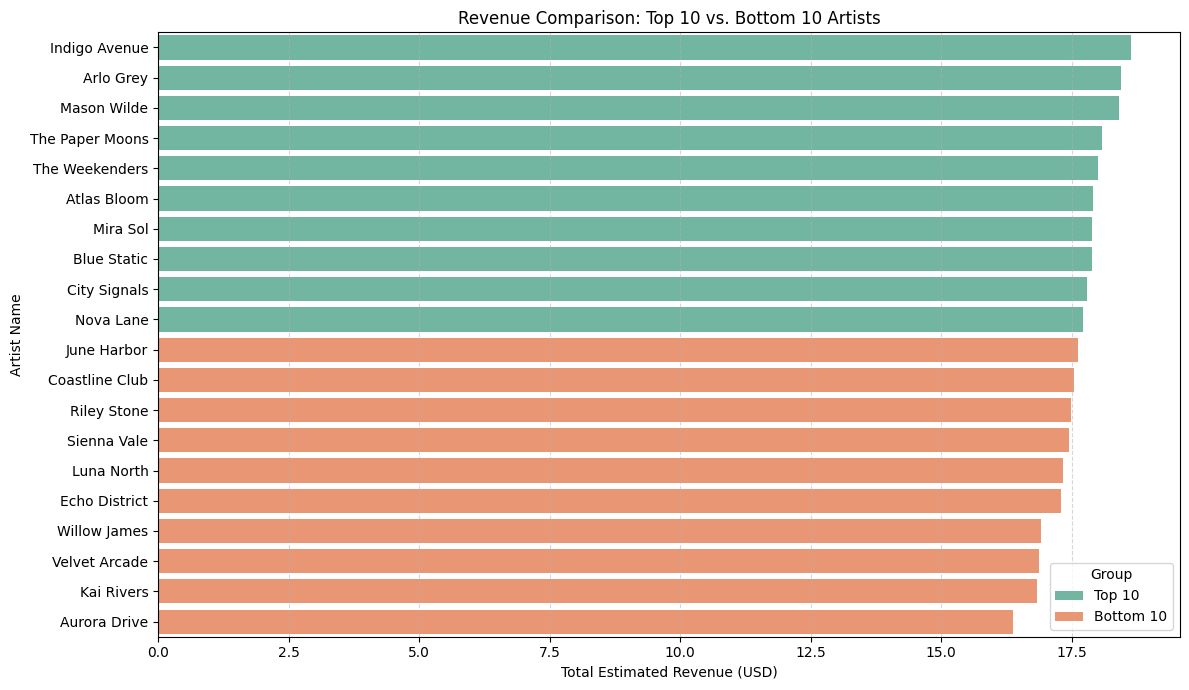

In [30]:
# Create a bar plot comparing the top 10 vs bottom 10 artists by revenue
plt.figure(figsize=(12, 7))
sn.barplot(data=comparison_df, x='Estimated Revenue USD', y='Artist Name', hue='Group', palette='Set2')
plt.title('Revenue Comparison: Top 10 vs. Bottom 10 Artists')
plt.xlabel('Total Estimated Revenue (USD)')
plt.ylabel('Artist Name')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

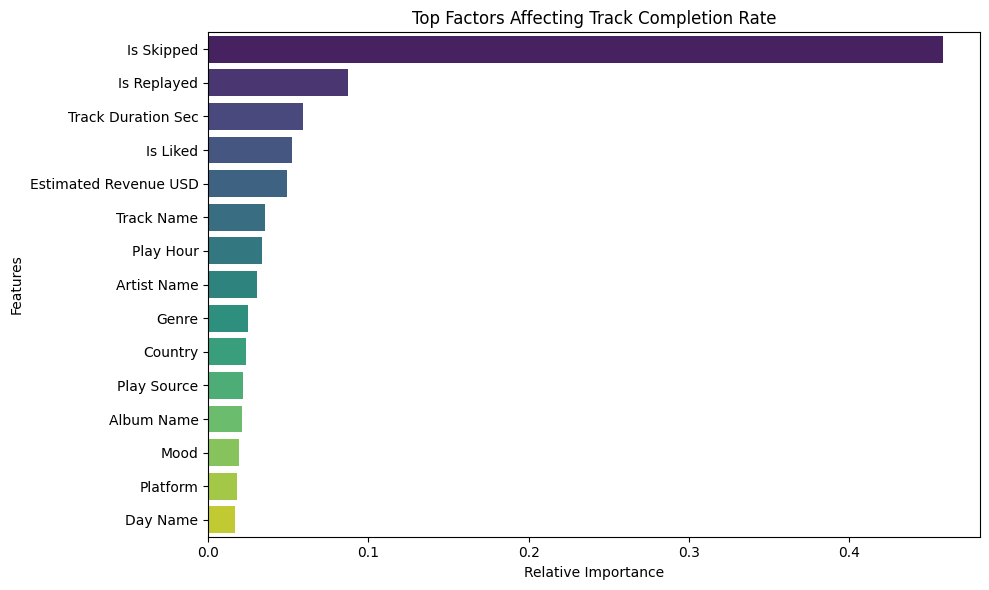

In [34]:
# Calculate and plot feature importances
importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(ascending=False, by='Importance')

plt.figure(figsize=(10, 6))
sn.barplot(data=feature_importance_df.head(15), x='Importance', y='Feature', palette='viridis', hue='Feature', legend=False)
plt.title('Top Factors Affecting Track Completion Rate')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

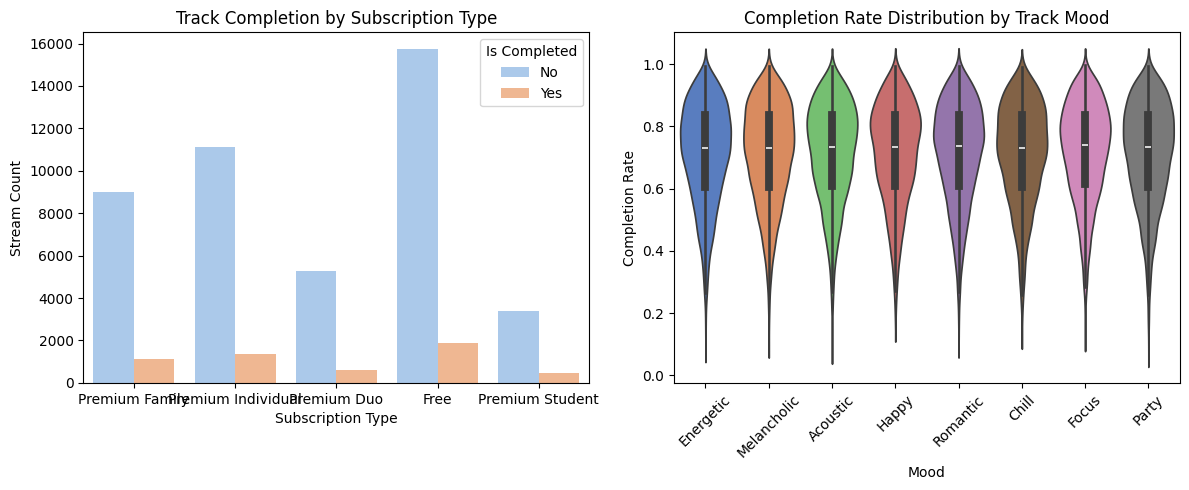

In [35]:
# 1. Stream Completions by Subscription Type
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sn.countplot(data=data, x='Subscription Type', hue='Is Completed', palette='pastel')
plt.title('Track Completion by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Stream Count')

# 2. Completion Rate across Different Track Moods
plt.subplot(1, 2, 2)
sn.violinplot(data=data, x='Mood', y='Completion Rate', hue='Mood', palette='muted', legend=False)
plt.title('Completion Rate Distribution by Track Mood')
plt.xlabel('Mood')
plt.ylabel('Completion Rate')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

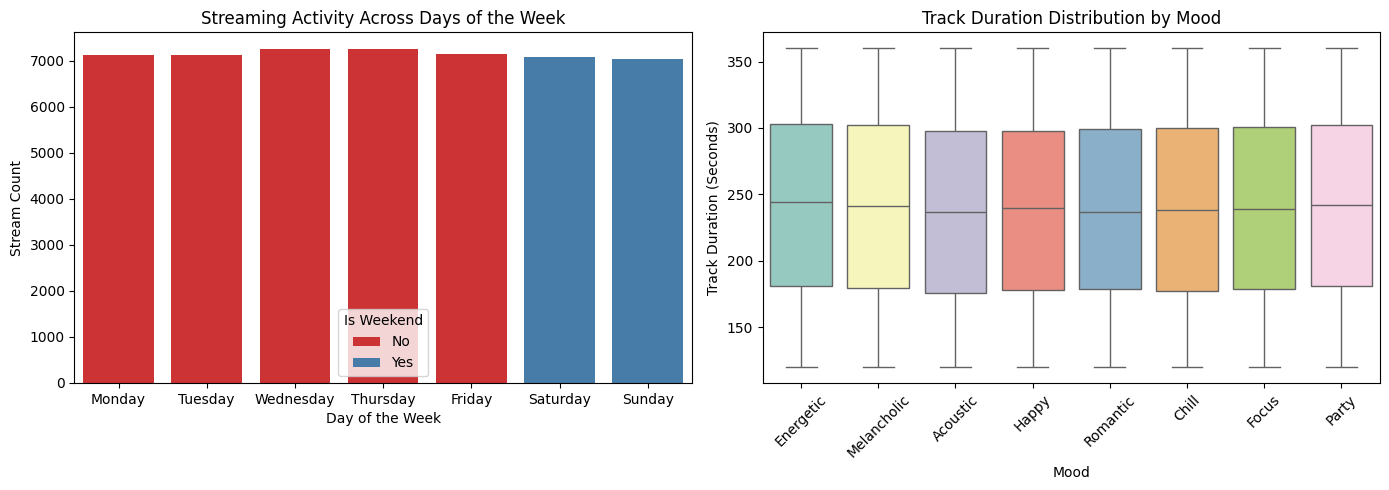

In [36]:
# Establish chronological order for days of the week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(14, 5))

# 1. Day of the Week Stream Distribution
plt.subplot(1, 2, 1)
sn.countplot(data=data, x='Day Name', order=day_order, hue='Is Weekend', palette='Set1')
plt.title('Streaming Activity Across Days of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Stream Count')

# 2. Track Duration by Mood
plt.subplot(1, 2, 2)
sn.boxplot(data=data, x='Mood', y='Track Duration Sec', hue='Mood', palette='Set3', legend=False)
plt.title('Track Duration Distribution by Mood')
plt.xlabel('Mood')
plt.ylabel('Track Duration (Seconds)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

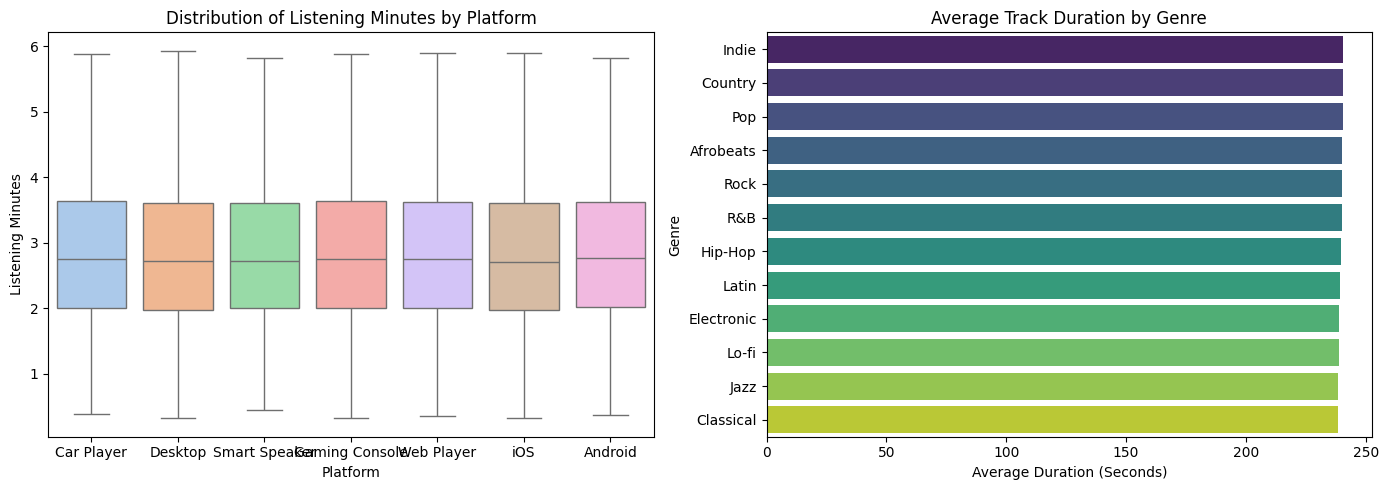

In [37]:
plt.figure(figsize=(14, 5))

# 1. Listening Minutes by Platform
plt.subplot(1, 2, 1)
sn.boxplot(data=data, x='Platform', y='Listening Minutes', hue='Platform', palette='pastel', legend=False)
plt.title('Distribution of Listening Minutes by Platform')
plt.xlabel('Platform')
plt.ylabel('Listening Minutes')

# Calculate average track duration by genre
avg_duration_genre = data.groupby('Genre')['Track Duration Sec'].mean().sort_values(ascending=False).reset_index()

# 2. Track Duration by Genre
plt.subplot(1, 2, 2)
sn.barplot(data=avg_duration_genre, x='Track Duration Sec', y='Genre', hue='Genre', palette='viridis', legend=False)
plt.title('Average Track Duration by Genre')
plt.xlabel('Average Duration (Seconds)')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

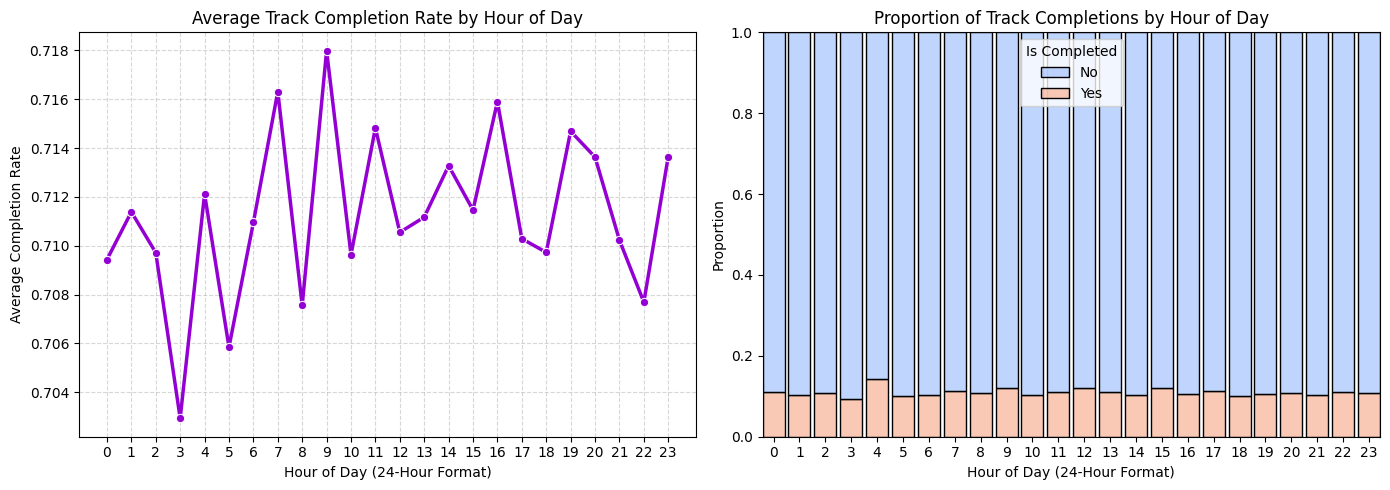

In [38]:
import matplotlib.pyplot as plt
import seaborn as sn

# Calculate average completion rate and count of streams by hour
hourly_completion = data.groupby('Play Hour')['Completion Rate'].mean().reset_index()

plt.figure(figsize=(14, 5))

# 1. Line plot: Mean Completion Rate by Hour of Day
plt.subplot(1, 2, 1)
sn.lineplot(data=hourly_completion, x='Play Hour', y='Completion Rate', marker='o', color='darkviolet', linewidth=2.5)
plt.title('Average Track Completion Rate by Hour of Day')
plt.xlabel('Hour of Day (24-Hour Format)')
plt.ylabel('Average Completion Rate')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(0, 24))

# 2. Density / Normalized Count Plot: Stream Completions by Hour of Day
plt.subplot(1, 2, 2)
sn.histplot(
    data=data,
    x='Play Hour',
    hue='Is Completed',
    multiple='fill',
    binwidth=1,
    discrete=True,
    palette='coolwarm',
    shrink=0.85
)
plt.title('Proportion of Track Completions by Hour of Day')
plt.xlabel('Hour of Day (24-Hour Format)')
plt.ylabel('Proportion')
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()